# Generating NDVI animations

* **Products used:** 
[ndvi_anomaly](https://explorer.digitalearth.africa/ndvi_anomaly)

## Background
This notebook shows how to generate an animation to visualise the NDVI across space, mean NDVI through time, and NDVI anomalies. It also generates a similar animation for monthly rainfall and rainfall anomalies.

Animations can help visualise changes in patterns through time. The visualisation of both mean values and anomalies means that seasonal and inter-annual aspects of time can be assessed. Complementing this with spatial images enhances interpretability of earth observation data.

## Description

The workflow for generating an animation progresses through the following steps:
1. Select an area of interest.
2. Load DE Africa Mean NDVI and Anomalies product.
3. Mask to cropland.
4. Generate NDVI animation.
5. Generate rainfall animation.
***

## Getting started

To run this analysis, run all the cells in the notebook, starting with the "Load packages and apps" cell.

### Load packages

In [1]:
%matplotlib inline

import os
import datacube
import datetime as dt
import xarray as xr
import geopandas as gpd
from odc.geo.geom import Geometry
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
import matplotlib.dates as mdates
from deafrica_tools.plotting import display_map
from deafrica_tools.areaofinterest import define_area

Connect to the datacube.

In [2]:
dc = datacube.Datacube(app='NDVI-animation')

### Analysis parameters

The default area is cropland in Madagascar.

---

The following cell sets the parameters, which define the area of interest and the length of time to conduct the analysis over.
The parameters are

* `lat`: The central latitude to analyse (e.g. `10.338`).
* `lon`: The central longitude to analyse (e.g. `-1.055`).
* `buffer`: The number of square degrees to load around the central latitude and longitude.
For reasonable loading times, set this as `0.1` or lower.


#### Select location
To define the area of interest, there are two methods available:

1. By specifying the latitude, longitude, and buffer. This method requires you to input the central latitude, central longitude, and the buffer value in square degrees around the center point you want to analyze. For example, `lat = 10.338`, `lon = -1.055`, and `buffer = 0.1` will select an area with a radius of 0.1 square degrees around the point with coordinates (10.338, -1.055).

    Alternatively, you can provide separate buffer values for latitude and longitude for a rectangular area. For example, `lat = 10.338`, `lon = -1.055`, and `lat_buffer = 0.1` and`lon_buffer = 0.08` will select a rectangular area extending 0.1 degrees north and south, and 0.08 degrees east and west from the point `(10.338, -1.055)`.

   For reasonable loading times, set the buffer as `0.1` or lower.

2. By uploading a polygon as a `GeoJSON or Esri Shapefile`. If you choose this option, you will need to upload the geojson or ESRI shapefile into the Sandbox using Upload Files button <img align="top" src="../Supplementary_data/upload_files_icon.png"> in the top left corner of the Jupyter Notebook interface. ESRI shapefiles must be uploaded with all the related files `(.cpg, .dbf, .shp, .shx)`. Once uploaded, you can use the shapefile or geojson to define the area of interest. Remember to update the code to call the file you have uploaded.

To use one of these methods, you can uncomment the relevant line of code and comment out the other one. To comment out a line, add the `"#"` symbol before the code you want to comment out. By default, the first option which defines the location using latitude, longitude, and buffer is being used.

**If running the notebook for the first time**, keep the default settings below.
This will demonstrate how the analysis works and provide meaningful results.

In [3]:
# # Define the area of interest for the analysis
year = "2021"

lat = 7.31112
lon = -1.57730
buffer = 0.05

# Method 1: Specify the latitude, longitude, and buffer
aoi = define_area(lat, lon, buffer)

# Method 2: Use a polygon as a GeoJSON or Esri Shapefile. 
# aoi = define_area(vector_path='aoi.shp')

#Create a geopolygon and geodataframe of the area of interest
geopolygon = Geometry(aoi["features"][0]["geometry"], crs="epsg:4326")
geopolygon_gdf = gpd.GeoDataFrame(geometry=[geopolygon], crs=geopolygon.crs)

# Get the latitude and longitude range of the geopolygon
lat_range = (geopolygon_gdf.total_bounds[1], geopolygon_gdf.total_bounds[3])
lon_range = (geopolygon_gdf.total_bounds[0], geopolygon_gdf.total_bounds[2])

display_map(lon_range, lat_range)

We will define the start and end date as the beginning and end of our year of interest.

In [4]:
start_date = dt.datetime.strptime(year, "%Y").replace(month=1, day=1)
end_date = dt.datetime.strptime(year, "%Y").replace(month=12, day=31)

Below, the analysis parameters are used to construct a query which loads the DE Africa mean NDVI and anomalies product.

In [5]:
# Construct the data cube query    
query = {
       'x': lon_range,
       'y': lat_range,
       'time': (start_date, end_date),
       'output_crs': 'EPSG:6933',
    'resolution': (-30, 30)
    }

ds = dc.load(product="ndvi_anomaly", **query)
ds

<xarray.Dataset> Size: 15MB
Dimensions:           (time: 12, y: 422, x: 322)
Coordinates:
  * time              (time) datetime64[ns] 96B 2021-01-16T11:59:59.999999 .....
  * y                 (y) float64 3kB 9.366e+05 9.365e+05 ... 9.24e+05 9.239e+05
  * x                 (x) float64 3kB -1.57e+05 -1.57e+05 ... -1.474e+05
    spatial_ref       int32 4B 6933
Data variables:
    ndvi_mean         (time, y, x) float32 7MB 0.3481 0.321 ... 0.6321 0.5963
    ndvi_std_anomaly  (time, y, x) float32 7MB -0.8718 -1.461 ... 0.595 0.3744
    clear_count       (time, y, x) int8 2MB 6 6 6 6 6 6 6 6 ... 8 8 8 8 8 8 8 8
Attributes:
    crs:           EPSG:6933
    grid_mapping:  spatial_ref

### Load cropland mask

This is an optional step for masking the NDVI data to cropland. In this instance, we are interested in inspecting crop vegetation patterns only, so we use the mask to do this.

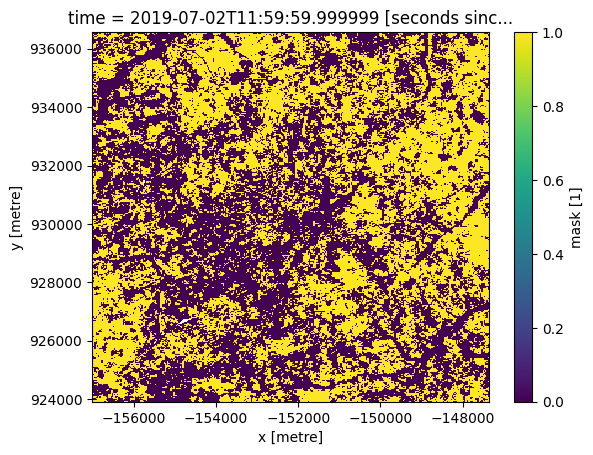

In [6]:
query = {
       'x': lon_range,
       'y': lat_range,
       'time': '2019',
       'output_crs': 'EPSG:6933',
    'resolution': (-30, 30),
    'measurements': 'mask'
    }

cm = dc.load(product='crop_mask', **query).squeeze()
cm.mask.where(cm.mask<255).plot()

### Mask NDVI to cropland

We mask the NDVI data to the cropland extent shown above.

In [7]:
ds = ds.where(cm.mask ==1)

## Prepare animation data

We need to prepare three objects for the animation:
1. Mean NDVI with spatial attributes.
2. Mean NDVI through time, aggregated as an average across space.
3. NDVI anomalies for each month, aggregated as an average across space.

In [8]:
ds_mean = ds.ndvi_mean

ds_mean_1D = ds_mean.mean(dim=['x', 'y'], skipna=True)

ndvi_anom = ds.ndvi_std_anomaly.mean(dim=['x', 'y']).to_dataframe().drop(['spatial_ref'], axis=1)

## Run animation

To create the animation, the cell below follows a few key steps:
1. Define the layout of the three axes and their size.
2. Set axis parameters (titles etc)
3. Start each axis with the first image of the animation (Januray).
4. Define an update function which adds each month sequentially to each of the three charts.
5. Run the animation.

Note the animation renders in its own window. The bottom right toggle enables download of the animation.

In [9]:
# create a figure and axes
fig = plt.figure()
fig.set_figheight(5)
fig.set_figwidth(10)


ax1 = plt.subplot2grid(shape=(2, 2), loc=(0, 1), colspan=2)
ax2 = plt.subplot2grid(shape=(2, 2), loc=(0, 0), rowspan=2)
ax3 = plt.subplot2grid(shape=(2, 2), loc=(1, 1), colspan=2)

# setup starting plot
cax = ds.ndvi_mean[0,:,:].plot(
    add_colorbar=True,
    cmap='RdYlGn',
    vmin=-1, vmax=1,
    cbar_kwargs={
        'extend':'neither'
    },
    ax=ax2
)

ax1.set_ylim([0, 1])
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax1.set_title("Mean NDVI")
ax1.set_xlabel("Date")
ax1.set_ylabel("NDVI")

ax3.set_ylim([-4, 4])
ax3.xaxis_date()
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax3.set_title("NDVI Anomaly")
ax3.set_xlabel("Date")
ax3.set_ylabel("Std Deviations from monthly mean")
ax3.axhline(0, color='black', linestyle='--')
    
x = ds_mean_1D.time
y = ds_mean_1D
                                                                         
x2 = ndvi_anom.index
y2 = [0] * ndvi_anom.ndvi_std_anomaly
bars = ax3.bar(x2, y2, align='center', width=20,color=(ndvi_anom.ndvi_std_anomaly > 0).map({True: 'g', False: 'brown'}))

line, = ax1.plot(x, y, marker='*',
                color='blue')

def update(num, x, y, x2, y2, bars, line):
    y2[num] = ndvi_anom.ndvi_std_anomaly[num]
    bars[num].set_height(y2[num])
    cax.set_array(ds.ndvi_mean[(num),:,:].values.flatten())
    ax2.set_title("Time = " + str(ds.ndvi_mean.coords['time'].values[(num)])[:12])
    line.set_data(x[:num+1], y[:num+1])
    return line,

plt.tight_layout()
ani = animation.FuncAnimation(fig, update, len(x), fargs=[x, y, x2, y2, bars, line],
                              interval=400, blit=False, repeat=True)
#ani.save('ndvi_anim.gif')

plt.close()  

HTML(ani.to_html5_video())

/tmp/ipykernel_1847/754916817.py:47: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  y2[num] = ndvi_anom.ndvi_std_anomaly[num]
/tmp/ipykernel_1847/754916817.py:47: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  y2[num] = ndvi_anom.ndvi_std_anomaly[num]
/tmp/ipykernel_1847/754916817.py:48: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  bars[num].set_height(y2[num])


# Make an NDVI animation with rainfall

The animation above summarises cropland NDVI in space and time, within a period of interest. We can add associated information to this visualisation, such as rainfall. The next few steps demonstrate how to load rainfall data and calculate anomalies for plotting.

## Rainfall anomaly parameters

We need to set some parameters for calculating the rainfall anomaly. The `time_m` period is a baseline period while `time_x` is the year of interest.

In [18]:
# Set the range of dates for the climatology, this will be the reference period (m) for the anomaly calculation.
# Standard practice is to use a 30 year period, so we've used 1981 to 2011 in this example.
time_m = ('2000', '2020')

# time period for monthly anomaly (x)
time_x = ('2021')

# CHIRPS has a spatial resolution of ~5x5 km
resolution = (-5000, 5000)

#size of dask chunks
dask_chunks = dict(x=500,y=500)

query_m = {
       'x': lon_range,
       'y': lat_range,
       'time': time_m,
       'output_crs': 'EPSG:6933',
    'resolution': (-5000, 5000)
    }

query_x = {
       'x': lon_range,
       'y': lat_range,
       'time': time_x,
       'output_crs': 'EPSG:6933',
    'resolution': (-5000, 5000)
    }

### Load rainfall data

In [19]:
ds_rf_m = dc.load(product='rainfall_chirps_monthly', **query_m)
ds_rf_x = dc.load(product='rainfall_chirps_monthly', **query_x)

Below, we calculate the monthly mean rainfall and anomaly.

In [20]:
# monthly means
climatology_mean = ds_rf_m.groupby('time.month').mean('time').compute()

#calculate monthly std dev
climatology_std = ds_rf_m.groupby('time.month').std('time').compute()

stand_anomalies = xr.apply_ufunc(
    lambda x, m, s: (x - m) / s,
    ds_rf_x.groupby("time.month"),
    climatology_mean,
    climatology_std,
    output_dtypes=[ds_rf_x.rainfall.dtype],
    dask="allowed"
).compute()

### Prepare animation data

As for the NDVI animation above, we need to prepare dataframes for the rainfall animation.

In [21]:
spatial_mean_rain = ds_rf_x.rainfall.mean(['x','y'])

spatial_mean_anoms = stand_anomalies.rainfall.mean(['x','y'], skipna=True).sel(
    time=slice(f'{year}-01-01', end_date)).to_dataframe().drop(
    ['spatial_ref', 'month'], axis=1).fillna(0)

print(len(spatial_mean_rain.time), len(spatial_mean_anoms))

12 12


## Run the animation

We follow the steps listed for the NDVI animation above to produce the rainfall animation.

In [22]:
# create a figure and axes
fig = plt.figure()
fig.set_figheight(5)
fig.set_figwidth(10)


ax1 = plt.subplot2grid(shape=(2, 2), loc=(0, 1), colspan=2)
ax2 = plt.subplot2grid(shape=(2, 2), loc=(0, 0), rowspan=2)
ax3 = plt.subplot2grid(shape=(2, 2), loc=(1, 1), colspan=2)

cax = ds.ndvi_mean[0,:,:].plot(
    add_colorbar=True,
    cmap='RdYlGn',
    vmin=-1, vmax=1,
    cbar_kwargs={
        'extend':'neither'
    },
    ax=ax2
)

ax1.set_title("Monthly Total Rainfall")
ax1.set_xlabel("Date")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax1.set_ylabel("Monthly Rainfall (mm)")

ax3.clear()
ax3.set_ylim([-4, 4])
ax3.xaxis_date()
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax3.set_title("Rainfall Anomaly")
ax3.set_xlabel("Date")
ax3.set_ylabel("Std Deviations from monthly mean")
ax3.axhline(0, color='black', linestyle='--')

def update(num, x, y, line):
    y2.iloc[num] =  spatial_mean_anoms.rainfall.iloc[num]
    bars[num].set_height(y2.iloc[num])
    cax.set_array(ds.ndvi_mean[(num),:,:].values.flatten())
    ax2.set_title("Time = " + str(ds.ndvi_mean.coords['time'].values[(num)])[:12])
    line.set_data(x[:num+1], y[:num+1])
    return line,
    
x = spatial_mean_rain.time
y = spatial_mean_rain
                                                                         
x2 = spatial_mean_anoms.index
y2 = [0] * spatial_mean_anoms.rainfall
bars = ax3.bar(x2, y2, align='center', width=20,color=(spatial_mean_anoms.rainfall > 0).map({True: 'b', False: 'r'}))

line, = ax1.plot(x, y, marker='*',
                color='blue')
plt.tight_layout()
ani = animation.FuncAnimation(fig, update, len(x), fargs=[x, y, line],
                              interval=400, blit=True)

ani.save('ndvi_rainfall_2021.gif', writer='pillow', fps=2)
plt.close()  

HTML(ani.to_html5_video())

In [23]:
import pandas as pd

ndvi_m = ds_mean_1D.to_series()
rain_m = spatial_mean_rain.to_series()
ndvi_m.index = ndvi_m.index.to_period('M')
rain_m.index = rain_m.index.to_period('M')
df = pd.DataFrame({'rain': rain_m, 'ndvi': ndvi_m}).dropna()
print(df.round(2))

seasons = {'Major season (Mar-Jul)': range(3, 8), 'Minor season (Aug-Dec)': range(8, 13)}
for name, months in seasons.items():
    s = df[df.index.month.isin(months)]
    print(name, '| rain peak:', s.rain.idxmax(), '| NDVI peak:', s.ndvi.idxmax())

for k in range(4):
    print(k, 'month delay, correlation:', round(df.rain.corr(df.ndvi.shift(-k)), 2))

               rain  ndvi
time                     
2021-01   20.620001  0.40
2021-02   33.849998  0.30
2021-03  146.369995  0.37
2021-04   88.980003  0.44
2021-05  126.169998  0.59
2021-06  128.330002  0.63
2021-07   93.169998  0.56
2021-08  178.889999  0.52
2021-09  294.720001  0.44
2021-10  214.990005  0.65
2021-11   73.150002  0.63
2021-12    4.640000  0.50
Major season (Mar-Jul) | rain peak: 2021-03 | NDVI peak: 2021-06
Minor season (Aug-Dec) | rain peak: 2021-09 | NDVI peak: 2021-10
0 month delay, correlation: 0.23
1 month delay, correlation: 0.67
2 month delay, correlation: 0.64
3 month delay, correlation: 0.0


## Findings

The animated GIF for 2021 shows vegetation greening up as rainfall increases through the two rainy seasons. Monthly CHIRPS rainfall peaked in March (146 mm) and September (295 mm), while mean NDVI peaked in June (0.63) and October (0.65). In the minor season, NDVI peaked about one month after the rainfall peak. In the major season, rainfall stayed high from March to June, and NDVI rose steadily from 0.37 in March to 0.63 in June, a green-up of roughly two to three months after the rains began. Lagged correlation confirmed this: NDVI correlated best with rainfall one to two months earlier (r = 0.67 and 0.64), against 0.23 with no lag. Because the data is monthly, these lags are accurate to about one month.

---

## Additional information

<b> License </b> The code in this notebook is licensed under the [Apache License, Version 2.0](https://www.apache.org/licenses/LICENSE-2.0).

Digital Earth Africa data is licensed under the [Creative Commons by Attribution 4.0](https://creativecommons.org/licenses/by/4.0/) license.

<b> Contact </b> If you need assistance, please post a question on the [DE Africa Slack channel](https://digitalearthafrica.slack.com/) or on the [GIS Stack Exchange](https://gis.stackexchange.com/questions/ask?tags=open-data-cube) using the `open-data-cube` tag (you can view previously asked questions [here](https://gis.stackexchange.com/questions/tagged/open-data-cube)).

If you would like to report an issue with this notebook, you can file one on [Github](https://github.com/digitalearthafrica/deafrica-sandbox-notebooks).

<b> Compatible datacube version </b>

In [ ]:
print(datacube.__version__)

**Last Tested:**

In [ ]:
from datetime import datetime
datetime.today().strftime('%Y-%m-%d')